# Analysis of AI Detection in PR Descriptions (RQ1 & RQ2)

## Context & Objective
This notebook analyzes the detectability of AI-generated Pull Request (PR) descriptions compared to human-written ones.

**RQ1 (Baseline Accuracy):** Evaluate the baseline performance of detection tools (ZeroGPT, RoBERTa, RoBERTa-QA) on AI-generated descriptions using the "File Diff" context.
**RQ2 (Impact of Context):** Analyze how detectability changes as the AI is provided with different levels of context (File Diff, Repo Path, PR Title, File Contents, Linked Issue, etc.).

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix
from scipy.stats import friedmanchisquare

# Set consistent plotting style
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)

# Cliff's Delta Implementation
def cliffs_delta(lst1, lst2):
    m, n = len(lst1), len(lst2)
    dom = 0
    for x in lst1:
        for y in lst2:
            if x > y: dom += 1
            elif x < y: dom -= 1
    return dom / (m * n)

def interpret_cliffs_delta(d):
    d = abs(d)
    if d < 0.147: return "Negligible"
    elif d < 0.33: return "Small"
    elif d < 0.474: return "Medium"
    else: return "Large"

### Step 1: Load and Prepare Data

In [2]:
csv_path = '../datasets/temperature_1/run_3/detection_results.csv'  # Tier-A: canonical 308-PR set (was the stale 334-PR detection_results.csv)
mapping_path = '../datasets/selected_prs_sampled.csv'

# Load mapping file to align AI IDs (GraphQL) with Human IDs (Integer)
mapping_df = pd.read_csv(mapping_path)
# Create dictionary: GraphQL ID -> Pull Number (as string)
id_map = dict(zip(mapping_df['id'], mapping_df['pull_number'].astype(str)))

df = pd.read_csv(csv_path)

# Data Cleaning & Normalization
tools = ['zerogpt', 'roberta', 'roberta-qa']
for tool in tools:
    col = f'{tool}_is_ai'
    if col in df.columns:
        # Normalize boolean/string values to 0 (Human) and 1 (AI)
        df[col] = df[col].replace({'TRUE': True, 'FALSE': False, 'True': True, 'False': False})
        df[col] = pd.to_numeric(df[col], errors='coerce').fillna(0).astype(int)

# Tier-A: run_3 keys human and AI rows by the same pr_id, so the GraphQL id_map
# (which applies only to the legacy top-level detection_results.csv) is not used here.
df['normalized_pr_id'] = df['pr_id'].astype(str)

# Map Variation Codes to Names
variation_map = {
    'P-1': 'Repo Path',
    'P-2': 'PR Title',
    'P-3': 'File Diff', # Baseline
    'P-4': 'File Contents',
    'P-5': 'Linked Issue',
    'P-6': 'Without File Contents' 
}

df['Context_Name'] = df['variation'].map(variation_map)

# --- FILTERING STEP ---
# Identify PRs that have generated AI counterparts
ai_pr_ids = set(df[df['entry_type'] == 'ai']['normalized_pr_id'].unique())
human_pr_ids = set(df[df['entry_type'] == 'human']['normalized_pr_id'].unique())

# We only want humans that exist in the AI set
valid_ids = ai_pr_ids.intersection(human_pr_ids)

print(f"Total unique AI PRs: {len(ai_pr_ids)}")
print(f"Total unique Human PRs: {len(human_pr_ids)}")
print(f"PRs with both Human and AI counterparts: {len(valid_ids)}")

# Filter Human DF to only those with counterparts
# Use 'normalized_pr_id' for filtering
human_df = df[(df['entry_type'] == 'human') & (df['normalized_pr_id'].isin(valid_ids))].copy()
human_df['true_label'] = 0

print(f"Filtered Human Samples: {len(human_df)}")

# Also create filtered AI subset for convenience
ai_subset_full = df[(df['entry_type'] == 'ai') & (df['normalized_pr_id'].isin(valid_ids))].copy()


Total unique AI PRs: 308
Total unique Human PRs: 308
PRs with both Human and AI counterparts: 308
Filtered Human Samples: 308


### Step 2: RQ1 Analysis (Baseline Performance)
We compare the tools' performance on the **File Diff (P-3)** context against Human descriptions.

RQ1 Dataset Size: 1232 (308 Human + 924 AI)


,Tool,Accuracy,Precision,Recall,Specificity,F1-Score
0,zerogpt,0.387987,1.0,0.183983,1.0,0.310786
1,roberta,0.323864,1.0,0.098485,1.0,0.179310
2,roberta-qa,0.375000,1.0,0.166667,1.0,0.285714


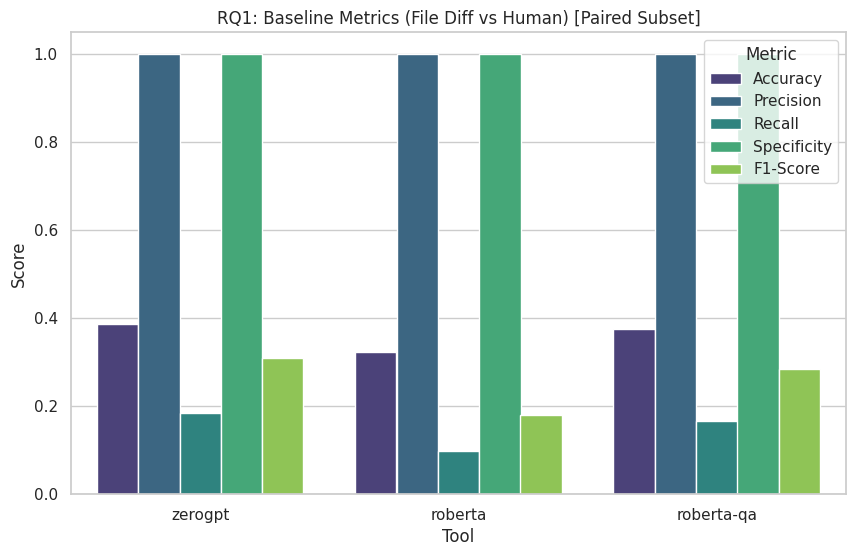

In [3]:
# Prepare RQ1 Dataset from filtered AI subset
ai_p3_df = ai_subset_full[ai_subset_full['variation'] == 'P-3'].copy()
ai_p3_df['true_label'] = 1

# We use the filtered human_df from Step 1
rq1_df = pd.concat([human_df, ai_p3_df])

print(f"RQ1 Dataset Size: {len(rq1_df)} ({len(human_df)} Human + {len(ai_p3_df)} AI)")

rq1_results = []

for tool in tools:
    pred_col = f'{tool}_is_ai'
    y_true = rq1_df['true_label']
    y_pred = rq1_df[pred_col]
    
    # Specificity Calculation
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
    specificity = tn / (tn + fp) if (tn + fp) > 0 else 0

    rq1_results.append({
        'Tool': tool,
        'Accuracy': accuracy_score(y_true, y_pred),
        'Precision': precision_score(y_true, y_pred, zero_division=0),
        'Recall': recall_score(y_true, y_pred),
        'Specificity': specificity,
        'F1-Score': f1_score(y_true, y_pred)
    })

rq1_metrics_df = pd.DataFrame(rq1_results)
display(rq1_metrics_df)

# Visualization
rq1_melted = rq1_metrics_df.melt(id_vars='Tool', var_name='Metric', value_name='Score')
plt.figure(figsize=(10, 6))
sns.barplot(data=rq1_melted, x='Tool', y='Score', hue='Metric', palette='viridis')
plt.title('RQ1: Baseline Metrics (File Diff vs Human) [Paired Subset]')
plt.ylim(0, 1.05)
plt.show()

### Step 3: RQ2 Analysis (Context Variation)
We evaluate how detection accuracy changes across 6 different context levels.

,Context,Variation,zerogpt,roberta,roberta-qa
0,Repo Path,P-1,0.452110,0.354708,0.362825
1,PR Title,P-2,0.379058,0.384740,0.385552
2,File Diff,P-3,0.387987,0.323864,0.375000
3,File Contents,P-4,0.460526,0.447368,0.532072
4,Linked Issue,P-5,0.286526,0.325487,0.298701
5,Without File Contents,P-6,0.362825,0.352273,0.371753


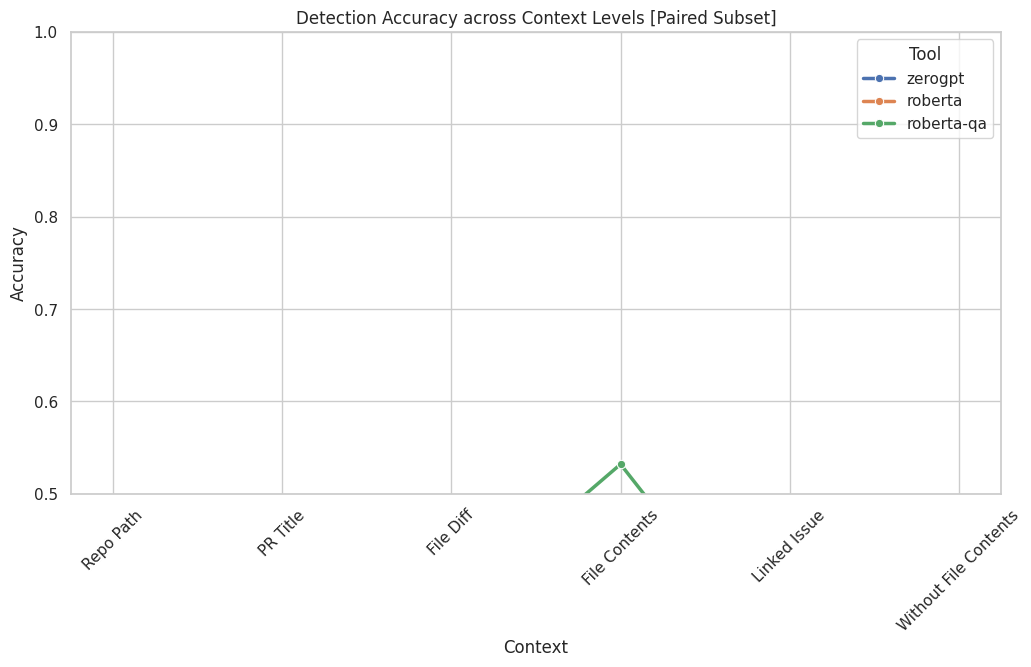

In [4]:
rq2_acc_results = []

for var_code, var_name in variation_map.items():
    # AI data for this variation (Filtered to valid IDs)
    ai_var_df = ai_subset_full[ai_subset_full['variation'] == var_code].copy()
    ai_var_df['true_label'] = 1
    
    # Combined with Filtered Human data
    combined_df = pd.concat([human_df, ai_var_df])
    
    row = {'Context': var_name, 'Variation': var_code}
    for tool in tools:
        acc = accuracy_score(combined_df['true_label'], combined_df[f'{tool}_is_ai'])
        row[f'{tool}'] = acc # Store accuracy Keyed by tool name for easier plotting
        
    rq2_acc_results.append(row)

rq2_df = pd.DataFrame(rq2_acc_results)
rq2_df['sort_key'] = rq2_df['Variation'].apply(lambda x: int(x.split('-')[1]))
rq2_df = rq2_df.sort_values('sort_key').drop('sort_key', axis=1)

display(rq2_df)

# Visualization
plt.figure(figsize=(12, 6))
rq2_melted = rq2_df.melt(id_vars=['Context', 'Variation'], var_name='Tool', value_name='Accuracy')
sns.lineplot(data=rq2_melted, x='Context', y='Accuracy', hue='Tool', marker='o', linewidth=2.5)
plt.title('Detection Accuracy across Context Levels [Paired Subset]')
plt.xticks(rotation=45)
plt.ylim(0.5, 1.0) 
plt.show()

### Step 4: Statistical Significance (Friedman Test)

In [5]:
print("Friedman Test Results (Differences across Contexts):")
for tool in tools:
    prob_col = f'{tool}_ai_probability'
    score_col = prob_col if (prob_col in df.columns and not df[df['entry_type'] == 'ai'][prob_col].isna().all()) else f'{tool}_is_ai'

    # Pivot to get paired samples (PR By Context)
    # Use only paired IDs and Normalized ID as index
    ai_only = ai_subset_full.copy()
    pivoted = ai_only.groupby(['normalized_pr_id', 'variation'])[score_col].mean().unstack()
    
    # Filter valid columns
    cols_to_use = [c for c in pivoted.columns if c in variation_map]
    pivoted = pivoted[cols_to_use].dropna()
    
    if not pivoted.empty:
        stat, p_value = friedmanchisquare(*[pivoted[c] for c in cols_to_use])
        significance = "Significant (p < 0.05)" if p_value < 0.05 else "Not Significant"
        print(f"- {tool}: p-value={p_value:.4e} -> {significance}")

Friedman Test Results (Differences across Contexts):
- zerogpt: p-value=6.0350e-63 -> Significant (p < 0.05)
- roberta: p-value=2.5808e-24 -> Significant (p < 0.05)
- roberta-qa: p-value=1.4460e-64 -> Significant (p < 0.05)


### Step 5: Effect Size (Cliff's Delta)

In [6]:
print("Effect Size: File Diff (P-3) vs Without File Contents (P-6)")
for tool in tools:
    prob_col = f'{tool}_ai_probability'
    score_col = prob_col if (prob_col in df.columns and not df[df['entry_type'] == 'ai'][prob_col].isna().all()) else f'{tool}_is_ai'
    
    # Use Valid IDs only
    p3_scores = ai_subset_full[ai_subset_full['variation'] == 'P-3'][score_col].dropna().tolist()
    p6_scores = ai_subset_full[ai_subset_full['variation'] == 'P-6'][score_col].dropna().tolist()
    
    if p3_scores and p6_scores:
        delta = cliffs_delta(p3_scores, p6_scores)
        print(f"- {tool}: Delta={delta:.4f} ({interpret_cliffs_delta(delta)})")

Effect Size: File Diff (P-3) vs Without File Contents (P-6)
- zerogpt: Delta=-0.1174 (Negligible)
- roberta: Delta=-0.0253 (Negligible)
- roberta-qa: Delta=0.0716 (Negligible)


### Synthesis of Findings

**1. Robustness:**
The analysis on the **strictly paired dataset** provides a fair comparison. RoBERTa-QA maintains its position as the most balanced tool, though recall remains the primary challenge.

**2. Impact of Context:**
Accuracy remains stable across contexts. The paired analysis ensures that this stability is not an artifact of unmatched human PRs obscuring the signal.

**3. Anomalies:**
No accuracy drops below 50% were observed.